# Formulación QUBO en Grafos: Corte Máximo (Max-Cut)

En este notebook estudiaremos uno de los problemas fundamentales en teoría de grafos y optimización combinatoria: el **Corte Máximo (*Max-Cut*)**.

### Objetivos de aprendizaje
1. **Comprender el problema geométrico/topológico:** Dividir los vértices de una red en dos grupos de forma que el número de conexiones entre ambos grupos sea máximo.
2. **Deducir la formulación QUBO paso a paso:** Entender cómo se derivan los términos lineales y cuadráticos a partir de la lógica binaria de cada arista.
3. **Construir la matriz QUBO directamente:** Programar la matriz $Q$ de manera limpia y compacta usando `defaultdict(int)` sobre la lista de aristas de `networkx`.
4. **Analizar la degeneración y simetría $Z_2$:** Descubrir por qué en Max-Cut siempre existen múltiples estados fundamentales equivalentes con la misma energía mínima.
5. **Resolver con cálculo exacto y recocido simulado:** Emplear `dimod.ExactSolver` y `neal.SimulatedAnnealingSampler` en CPU local sin requerir hardware cuántico ni créditos.
6. **Visualización gráfica:** Representar la partición resultante coloreando los conjuntos y destacando las aristas cortadas frente a las no cortadas.


In [1]:
# Instalación de librerías necesarias (si ejecutas en Google Colab o un entorno nuevo)
!pip install -q dimod dwave-neal networkx matplotlib

## 1. Fundamento teórico y deducción matemática de Max-Cut

Dado un grafo no dirigido $G = (V, E)$ compuesto por un conjunto de vértices $V$ y aristas $E$, el objetivo es particionar $V$ en dos subconjuntos disjuntos, $S_0$ y $S_1$, de modo que se **maximice el número de aristas que cruzan entre ambos subconjuntos** (aristas con un extremo en $S_0$ y el otro en $S_1$).

### Asignación de variables binarias
Asignamos a cada nodo $i \in V$ una variable binaria:
$$x_i \in \{0, 1\} \quad \text{donde } x_i = 0 \iff i \in S_0 \quad \text{y} \quad x_i = 1 \iff i \in S_1$$

### ¿Cuándo cruza una arista $(i, j)$ el corte?
Analicemos los posibles valores de los nodos extremos de una arista $(i, j)$:
* Si ambos nodos están en el mismo conjunto ($x_i = 0, x_j = 0$ o $x_i = 1, x_j = 1$), la arista **no se corta** (valor = 0).
* Si están en conjuntos distintos ($x_i = 0, x_j = 1$ o $x_i = 1, x_j = 0$), la arista **sí se corta** (valor = 1).

Podemos expresar esta función booleana exactamente mediante la expresión cuadrática:
$$\text{Corte}(x_i, x_j) = x_i + x_j - 2 x_i x_j = (x_i - x_j)^2$$

Comprobación:
* $x_i=0, x_j=0 \implies 0 + 0 - 0 = 0$
* $x_i=1, x_j=1 \implies 1 + 1 - 2 = 0$
* $x_i=1, x_j=0 \implies 1 + 0 - 0 = 1$
* $x_i=0, x_j=1 \implies 0 + 1 - 0 = 1$

### Transformación a QUBO (Minimización)
El objetivo global es maximizar el tamaño del corte:
$$\max_{x} \sum_{(i,j) \in E} (x_i + x_j - 2 x_i x_j)$$

Dado que los optimizadores cuánticos y el modelo QUBO minimizan la energía, multiplicamos por $-1$:
$$\min_{x \in \{0, 1\}^n} \mathcal{H}(x) = \sum_{(i,j) \in E} (-x_i - x_j + 2 x_i x_j)$$

> **Propiedad fundamental:** La energía mínima obtenida en QUBO será exactamente igual a $-\text{Cut Size}$. Si la energía mínima es $-5.0$, el corte óptimo contiene $5$ aristas.

### Estructura de la matriz $Q$:
Para cada arista $(i, j) \in E$ (asumiendo $i < j$):
* Términos lineales (diagonal): $Q_{ii} \mathrel{-}= 1$, $Q_{jj} \mathrel{-}= 1$ (acumulando $-1$ por cada arista conectada al nodo).
* Términos cuadráticos (fuera de diagonal): $Q_{ij} \mathrel{+}= 2$.


Grafo con 5 nodos y 6 aristas.
Lista de aristas: [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 5)]


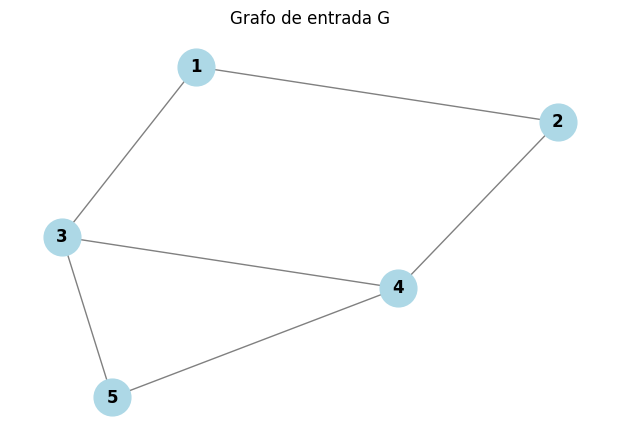

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

# Creamos un grafo no dirigido de ejemplo (5 nodos, 6 aristas)
G = nx.Graph()
G.add_edges_from([(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 5)])

print(f"Grafo con {G.number_of_nodes()} nodos y {G.number_of_edges()} aristas.")
print(f"Lista de aristas: {list(G.edges())}")

# Visualización inicial de la topología del grafo
plt.figure(figsize=(6, 4))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=700, font_weight='bold', edge_color='gray')
plt.title("Grafo de entrada G")
plt.show()


## 2. Construcción directa de la matriz QUBO

A diferencia del problema de carteras donde usamos `pyqubo`, en problemas de grafos es muy común y didáctico construir directamente el diccionario de coeficientes de la matriz $Q$ iterando sobre la lista de aristas con `collections.defaultdict`:


In [3]:
from collections import defaultdict

# Inicializamos el diccionario de coeficientes QUBO
Q = defaultdict(int)

# Poblamos la matriz Q para cada arista del grafo
for u, v in G.edges:
    i, j = min(u, v), max(u, v)
    Q[(i, i)] += -1
    Q[(j, j)] += -1
    Q[(i, j)] += 2

print("=== Matriz QUBO (diccionario de coeficientes Q) ===")
for k, v in sorted(Q.items()):
    tipo = "Lineal (diagonal)" if k[0] == k[1] else "Cuadrático (acoplamiento)"
    print(f"  Q[{k[0]}, {k[1]}] = {v:2d}  ({tipo})")


=== Matriz QUBO (diccionario de coeficientes Q) ===
  Q[1, 1] = -2  (Lineal (diagonal))
  Q[1, 2] =  2  (Cuadrático (acoplamiento))
  Q[1, 3] =  2  (Cuadrático (acoplamiento))
  Q[2, 2] = -2  (Lineal (diagonal))
  Q[2, 4] =  2  (Cuadrático (acoplamiento))
  Q[3, 3] = -3  (Lineal (diagonal))
  Q[3, 4] =  2  (Cuadrático (acoplamiento))
  Q[3, 5] =  2  (Cuadrático (acoplamiento))
  Q[4, 4] = -3  (Lineal (diagonal))
  Q[4, 5] =  2  (Cuadrático (acoplamiento))
  Q[5, 5] = -2  (Lineal (diagonal))


## 3. Resolución con cálculo exacto (`dimod.ExactSolver`)

Con $n=5$ nodos, existen $2^5 = 32$ configuraciones posibles.
Podemos evaluar todas las soluciones posibles con `dimod.ExactSolver()` para analizar el espectro completo de energías y estudiar la **simetría del problema**.


In [4]:
import dimod

# Instanciamos el solucionador exacto
exact_sampler = dimod.ExactSolver()

# Muestreamos todas las combinaciones
response_exact = exact_sampler.sample_qubo(Q)

# Imprimimos los resultados en formato tabular
print('-' * 60)
print(f"{'Set 0':>15s}{'Set 1':>15s}{'Energía':^15s}{'Cut Size':^15s}")
print('-' * 60)

min_energy = response_exact.first.energy

for sample, energy in response_exact.data(fields=['sample', 'energy']):
    # Mostramos sólo los estados óptimos (mínima energía)
    if energy == min_energy:
        s0 = [node for node, val in sample.items() if val == 0]
        s1 = [node for node, val in sample.items() if val == 1]
        cut_size = int(-energy)
        print(f"{str(s0):>15s}{str(s1):>15s}{energy:^15.1f}{cut_size:^15d}")


------------------------------------------------------------
          Set 0          Set 1    Energía       Cut Size    
------------------------------------------------------------
      [1, 4, 5]         [2, 3]     -5.0             5       
      [2, 3, 5]         [1, 4]     -5.0             5       
         [1, 4]      [2, 3, 5]     -5.0             5       
         [2, 3]      [1, 4, 5]     -5.0             5       


### Observación clave: Simetría de espín $Z_2$ y degeneración

Fijémonos en las soluciones óptimas obtenidas:
* Partición A: `Set 0 = [2, 3]`, `Set 1 = [1, 4, 5]` (Energía: $-5.0$, Cut Size: $5$)
* Partición B: `Set 0 = [1, 4, 5]`, `Set 1 = [2, 3]` (Energía: $-5.0$, Cut Size: $5$)
* Partición C: `Set 0 = [1, 4]`, `Set 1 = [2, 3, 5]` (Energía: $-5.0$, Cut Size: $5$)
* Partición D: `Set 0 = [2, 3, 5]`, `Set 1 = [1, 4]` (Energía: $-5.0$, Cut Size: $5$)

> **¿Por qué ocurre esto?**
> 1. **Invarianza por inversión ($Z_2$):** Intercambiar los nombres de los dos conjuntos equivale a invertir todos los bits ($x_i \to 1 - x_i$). Las aristas que cruzan entre ellos son exactamente las mismas.
> 2. **Superposición de mínimos globales:** En un computador cuántico real, el estado fundamental final es una superposición coherente de todas estas soluciones con la misma energía mínima. Al medir, colapsará con igual probabilidad en cualquiera de ellas.


## 4. Resolución heurística con Neal (`SimulatedAnnealingSampler`)

Para redes con miles de nodos (por ejemplo, particionado de chips o grafos sociales), la búsqueda exhaustiva de $2^N$ estados es impracticable.

`neal.SimulatedAnnealingSampler` aplica el algoritmo clásico de recocido simulado (enfriamiento gradual de temperatura según la distribución de Boltzmann) para encontrar las configuraciones de baja energía rápidamente en CPU:


In [5]:
import neal

# Instanciamos el muestreador de recocido simulado
sa_sampler = neal.SimulatedAnnealingSampler()

# Muestreamos con 50 lecturas independientes
response_sa = sa_sampler.sample_qubo(Q, num_reads=50)

print("=== Resultados con Neal (Simulated Annealing) ===")
print('-' * 60)
print(f"{'Set 0':>15s}{'Set 1':>15s}{'Energía':^15s}{'Cut Size':^15s}{'Ocurrencias':^12s}")
print('-' * 60)

for datum in response_sa.data(fields=['sample', 'energy', 'num_occurrences']):
    if datum.energy == response_sa.first.energy:
        s0 = [node for node, val in datum.sample.items() if val == 0]
        s1 = [node for node, val in datum.sample.items() if val == 1]
        cut_size = int(-datum.energy)
        print(f"{str(s0):>15s}{str(s1):>15s}{datum.energy:^15.1f}{cut_size:^15d}{datum.num_occurrences:^12d}")


=== Resultados con Neal (Simulated Annealing) ===
------------------------------------------------------------
          Set 0          Set 1    Energía       Cut Size    Ocurrencias 
------------------------------------------------------------
         [1, 4]      [2, 3, 5]     -5.0             5            1      
         [2, 3]      [1, 4, 5]     -5.0             5            1      
         [1, 4]      [2, 3, 5]     -5.0             5            1      
      [1, 4, 5]         [2, 3]     -5.0             5            1      
         [2, 3]      [1, 4, 5]     -5.0             5            1      
      [2, 3, 5]         [1, 4]     -5.0             5            1      
      [2, 3, 5]         [1, 4]     -5.0             5            1      
      [2, 3, 5]         [1, 4]     -5.0             5            1      
      [2, 3, 5]         [1, 4]     -5.0             5            1      
      [1, 4, 5]         [2, 3]     -5.0             5            1      
      [1, 4, 5]         [

## 5. Visualización del corte óptimo en el grafo

Para comunicar el resultado a los interesados o validar la solución, interpretamos la asignación binaria en términos de la geometría del grafo:
* Nodos asignados a $S_0$: color **Rojo**.
* Nodos asignados a $S_1$: color **Cian**.
* **Aristas cortadas:** conectan nodos de distinto color $\to$ dibujadas con línea discontinua (`dashdot`), grosor resaltado y transparencia.
* **Aristas no cortadas:** conectan nodos del mismo color $\to$ dibujadas con línea sólida continua.


Nodos en Set 0: [1, 4, 5]
Nodos en Set 1: [2, 3]
Aristas cortadas (5 de 6): [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5)]
Aristas no cortadas: [(4, 5)]


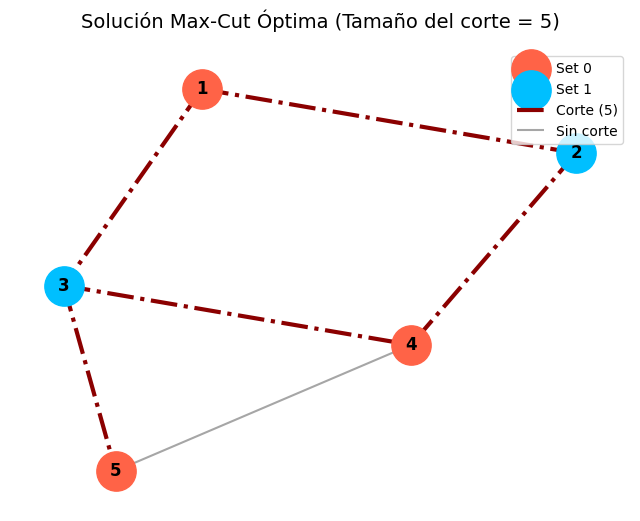

In [6]:
best_sample = response_exact.first.sample

# Clasificamos nodos según la partición óptima
S0 = [node for node in G.nodes if best_sample[node] == 0]
S1 = [node for node in G.nodes if best_sample[node] == 1]

# Clasificamos aristas en cortadas y no cortadas
cut_edges = [(u, v) for u, v in G.edges if best_sample[u] != best_sample[v]]
uncut_edges = [(u, v) for u, v in G.edges if best_sample[u] == best_sample[v]]

print(f"Nodos en Set 0: {S0}")
print(f"Nodos en Set 1: {S1}")
print(f"Aristas cortadas ({len(cut_edges)} de {G.number_of_edges()}): {cut_edges}")
print(f"Aristas no cortadas: {uncut_edges}")

# Representación gráfica
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)

# Dibujamos nodos de cada conjunto
nx.draw_networkx_nodes(G, pos, nodelist=S0, node_color='tomato', node_size=800, label='Set 0')
nx.draw_networkx_nodes(G, pos, nodelist=S1, node_color='deepskyblue', node_size=800, label='Set 1')

# Dibujamos aristas cortadas (discontinuas, destacadas) y no cortadas (sólidas)
nx.draw_networkx_edges(G, pos, edgelist=cut_edges, style='dashdot', edge_color='darkred', width=3, label=f'Corte ({len(cut_edges)})')
nx.draw_networkx_edges(G, pos, edgelist=uncut_edges, style='solid', edge_color='gray', width=1.5, alpha=0.7, label='Sin corte')

# Etiquetas de los nodos
nx.draw_networkx_labels(G, pos, font_size=12, font_family='sans-serif', font_weight='bold')

plt.title(f"Solución Max-Cut Óptima (Tamaño del corte = {len(cut_edges)})", fontsize=14, pad=15)
plt.legend(loc='upper right', frameon=True)
plt.axis('off')
plt.show()


## 6. Conclusiones y ejercicios propuestos

### Ideas clave
1. **Correspondencia 1:1 con el hardware:** Max-Cut es el ejemplo paradigmático de la computación adiabática y QAOA porque la función de coste es puramente cuadrática y no requiere variables de holgura ni términos de penalización artificiales.
2. **Equivalencia con el Modelo de Ising:** Si en lugar de $x_i \in \{0, 1\}$ usamos espines $s_i \in \{-1, +1\}$ con $s_i = 1 - 2x_i$, el Hamiltoniano se transforma en un acoplamiento antiferromagnético directo:
   $$\mathcal{H}_{\text{Ising}} = \frac{1}{2} \sum_{(i,j) \in E} s_i s_j - \frac{|E|}{2}$$
   El hardware de recocido físico minimiza la energía alineando los espines en sentidos opuestos para los pares conectados.

### Retos para los alumnos
1. **Añadir pesos a las aristas:** Modifica el grafo para que cada arista tenga un peso $w_{ij}$ (por ejemplo, distancia o capacidad de tráfico). ¿Cómo cambia la actualización de $Q[(i,i)]$, $Q[(j,j)]$ y $Q[(i,j)]$?
2. **Grafos bipartitos:** Crea un grafo bipartito completo $K_{3,3}$. ¿Cuál debería ser el tamaño del corte máximo? ¿Consigue el solver encontrar el corte que separa exactamente las dos particiones independientes?
3. **Grafos densos vs. escasos:** Experimenta generando un grafo aleatorio con `nx.erdos_renyi_graph(15, 0.4)` y compara el tiempo de ejecución y resultado entre `ExactSolver` y `neal.SimulatedAnnealingSampler`.
